# Mapa de riesgo 2027 por distrito
## ¿Qué distritos de la costa norte tendrían alta incidencia de emergencias por lluvias en enero-mayo de 2027?

**Curso:** IS281 Analítica de datos y sistemas predictivos (UPC) · **Librería:** scikit-learn

Este notebook estima, para cada distrito, la probabilidad de tener **100 damnificados o más** por lluvias entre
enero y mayo de 2027 (`alta_incidencia`).

**El problema de fondo.** El Niño 2026-27 ya superó todo lo registrado: el ICEN de setiembre de 2026 (4,50) es el
valor mensual más alto de la serie. Un modelo que aprende del pasado no sabe qué pasa con algo más grande que lo
que vio. Por eso este notebook:

1. **Separa clima e impacto.** No intenta predecir cuánto lloverá: eso lo dicen los modelos climáticos de ENFEN y
   SENAMHI. Toma la lluvia como **escenario** y estima el daño que causaría.
2. **Agrega escenarios más extremos que cualquier año:** el peor caso por distrito y la lluvia de 1998 aumentada en
   25 % y 50 %.
3. **Usa dos modelos:** el Random Forest del notebook 02, que ordena mejor los distritos pero no extrapola, y una
   regresión logística, que sí sigue subiendo cuando la lluvia supera lo visto. El mapa usa el promedio de los dos
   y las tablas muestran el rango.

**Qué es y qué no es.**
- Es un ranking de riesgo entre distritos bajo cada escenario: dónde conviene mirar primero.
- No dice qué día ni qué calles se inundan, y no mide el área inundada.
- Es un ejercicio académico. Las alertas oficiales son las de ENFEN, SENAMHI e INDECI.

Contenido:
1. Datos y variables
2. ¿Se puede corregir 1998?
3. Supuestos de 2027
4. Escenarios de lluvia
5. Los dos modelos y su validación
6. Predicción 2027
7. Mapa de riesgo
8. Distritos prioritarios
9. ¿Cuánto cambia si el ICEN es otro?
10. Archivos
11. Conclusiones

## 1. Datos y variables

Es la tabla distrito × temporada del notebook 02. Hay dos grupos de variables:

- **ESCENARIO** (Random Forest): ICEN antes y durante la temporada, lluvia, historial y atributos del distrito.
  Son las mismas del notebook 02.
- **IMPACTO** (regresión logística): solo lluvia de enero a mayo, historial y atributos del distrito, **sin ICEN**.
  Es el eslabón "lluvia → daño". El ICEN ya está dentro del escenario de lluvia que se elija.

En la regresión logística, las variables muy sesgadas (población, superficie, cuencas, lluvia en mm) se pasan a
logaritmo.

In [1]:
from pathlib import Path
import json
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from shapely.geometry import shape
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "2_limpios").exists())
LIMPIOS = RAIZ / "datos" / "2_limpios"
RESULTADOS = RAIZ / "resultados"
SEMILLA = 42
UMBRAL_ALTA = 100
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(LIMPIOS / "modelo" / "panel_distrito_temporada_1970_2025.csv", dtype={"ubigeo": str})
df["alta_incidencia"] = (df.damnificados >= UMBRAL_ALTA).astype(int)
df["es_indeci"] = (df.fuente_objetivo == "INDECI").astype(int)
for d in ["TUMBES", "PIURA", "LAMBAYEQUE", "LA LIBERTAD"]:  # Áncash queda como referencia
    df["dep_" + d.lower().replace(" ", "_")] = (df.departamento == d).astype(int)

FIJOS = ["superficie_km2", "poblacion_2020_estimada", "pob_densidad_2020", "idh_2019", "pct_pobreza_total",
         "pct_pobreza_extrema", "indice_vulnerabilidad_alimentaria", "altitud_capital_m", "lat_centroide",
         "lon_centroide", "elev_media_m", "elev_min_m", "elev_p10_m", "pct_area_bajo_50m", "pct_area_bajo_200m",
         "pendiente_media_grados", "pct_area_pendiente_menor_2", "dist_centroide_a_rio_mayor_km",
         "cuenca_max_que_cruza_km2", "dep_tumbes", "dep_piura", "dep_lambayeque", "dep_la_libertad"]
ENSO_ANTES = ["icen_nov_previo", "icen_max_jun_nov_previo", "icen_cambio_ago_nov_previo", "nino34_anom_nov_previo"]
HIST = ["hist_tuvo_damnificados_temporada_anterior", "hist_temporadas_con_damnificados",
        "hist_pct_temporadas_con_damnificados"]
ENSO_TEMPORADA = ["icen_max_ene_may", "icen_medio_ene_may"]
LLUVIA_TEMPORADA = ["lluvia_ene_may_pisco_reciente_relativa", "lluvia_ene_may_chirps_relativa",
                    "lluvia_mes_max_ene_may_pisco_reciente_mm"]
LLUVIA = ["lluvia_nov_dic_previo_pisco_reciente_mm"] + LLUVIA_TEMPORADA
ESCENARIO = ENSO_ANTES + HIST + ["es_indeci"] + FIJOS + ENSO_TEMPORADA + LLUVIA
IMPACTO = HIST + ["es_indeci"] + FIJOS + LLUVIA_TEMPORADA
EN_LOGARITMO = ["superficie_km2", "poblacion_2020_estimada", "pob_densidad_2020", "cuenca_max_que_cruza_km2",
                "dist_centroide_a_rio_mayor_km", "lluvia_mes_max_ene_may_pisco_reciente_mm"]
print(f"{len(df):,} filas | {df.ubigeo.nunique()} distritos | ESCENARIO: {len(ESCENARIO)} variables | "
      f"IMPACTO: {len(IMPACTO)} variables")
print("Distritos con alta incidencia en los años de referencia:",
      df[df.anio.isin([1983, 1998, 2017, 2023])].groupby("anio").alta_incidencia.sum().to_dict())

20,384 filas | 364 distritos | ESCENARIO: 37 variables | IMPACTO: 30 variables
Distritos con alta incidencia en los años de referencia: {1983: 26, 1998: 40, 2017: 145, 2023: 123}


## 2. ¿Se puede corregir 1998?

Los damnificados de 1983 y 1998 vienen de DesInventar, que registró mucho menos que INDECI. Si el modelo aprende
de esos años, cree que una lluvia como la de 1998 hace menos daño del que hizo. La primera idea es multiplicar los
damnificados de DesInventar hasta llegar a las cifras que reportó INDECI para 1997-98.

In [2]:
comp = pd.read_csv(LIMPIOS / "emergencias" / "impactos_eventos_nino_compilados.csv")
reportado = comp[(comp.evento == "1997-98") & (comp.ambito == "departamento")
                 & (comp.indicador == "damnificados")].set_index("lugar").valor
fichas = pd.read_csv(LIMPIOS / "emergencias" / "desinventar_fichas_costa_norte.csv", low_memory=False)
periodo = fichas[((fichas.anio == 1997) & (fichas.mes_num == 12)) | ((fichas.anio == 1998) & (fichas.mes_num <= 6))]
comparacion = pd.DataFrame({
    "INDECI (dic-97 a jun-98)": reportado,
    "DesInventar (mismo periodo)": periodo.groupby("departamento").damnificados.sum().reindex(reportado.index)})
comparacion["veces"] = (comparacion.iloc[:, 0] / comparacion.iloc[:, 1]).round(1)
print("Damnificados de 1997-98:")
display(comparacion.astype({"INDECI (dic-97 a jun-98)": int}))

con_registro = pd.DataFrame({a: df[df.anio == a].groupby("departamento").damnificados.apply(lambda s: (s > 0).sum())
                             for a in [1983, 1998, 2017, 2023]})
print("Distritos con algún damnificado registrado en la temporada (enero-mayo):")
display(con_registro.loc[["TUMBES", "PIURA", "LAMBAYEQUE", "LA LIBERTAD", "ANCASH"]])

d98 = df[df.anio == 1998]
escalado = d98.damnificados * d98.departamento.map(comparacion["veces"]).fillna(1)
print(f"Distritos de 1998 con ≥ {UMBRAL_ALTA} damnificados: {(d98.damnificados >= UMBRAL_ALTA).sum()} sin corregir "
      f"y {(escalado >= UMBRAL_ALTA).sum()} multiplicando por esas veces.")
print("Piura 1998, damnificados de los distritos con registro:",
      sorted(d98[(d98.departamento == "PIURA") & (d98.damnificados > 0)].damnificados.tolist()))

Damnificados de 1997-98:


,INDECI (dic-97 a jun-98),DesInventar (mismo periodo),veces
lugar,,,
PIURA,120000,22411,5.4
LA LIBERTAD,72306,43812,1.7
LAMBAYEQUE,71756,28309,2.5


Distritos con algún damnificado registrado en la temporada (enero-mayo):


,1983,1998,2017,2023
departamento,,,,
TUMBES,6,6,9,11
PIURA,10,9,59,64
LAMBAYEQUE,5,5,38,37
LA LIBERTAD,3,9,44,68
ANCASH,7,19,91,93


Distritos de 1998 con ≥ 100 damnificados: 40 sin corregir y 40 multiplicando por esas veces.
Piura 1998, damnificados de los distritos con registro: [100, 150, 250, 500, 1550, 2700, 3000, 4968, 5000]


**Multiplicar no sirve.** DesInventar no anotó cifras bajas: anotó **pocos distritos**. En la temporada de
1998 registró daños en solo 9 distritos de Piura (en 2017 INDECI registró 59), y todos esos ya pasaban de 100
damnificados. Los demás distritos quedaron en cero, y multiplicar cero sigue dando cero.

**Decisión.** No se puede saber qué distritos faltan, así que 1998 no se corrige a mano. En cambio:
- la **regresión logística se entrena solo con los años de INDECI (2003-2025)**, que registran bien;
- la lluvia de 1998 se usa como **escenario**, no como ejemplo de daño;
- el Random Forest se deja como en el notebook 02 (1970-2025), porque así se validó.

## 3. Supuestos de 2027

Para 2027 se arma una fila por distrito con estos valores:

- **ICEN antes de la temporada:** el último ICEN publicado se usa como si fuera el de noviembre de 2026, que
  todavía no sale. Cuando ENFEN publique el de noviembre, se vuelve a correr el notebook.
- **ICEN de enero a mayo:** tu supuesto de `datos/2_limpios/escenarios/icen_2027_supuesto.csv`. Ese archivo llega
  hasta abril, así que el máximo y el promedio se calculan con enero-abril. Solo lo usa el Random Forest.
- **Historial:** las temporadas de 1970 a 2025. La de 2026 todavía no está en la base de INDECI, así que como
  "temporada anterior" se usa 2025.
- **Fuente:** `es_indeci = 1`, porque 2027 se medirá con INDECI.

In [3]:
enso = pd.read_csv(LIMPIOS / "enso" / "enso_mensual_1854_hoy.csv").set_index("fecha")
supuesto = pd.read_csv(LIMPIOS / "escenarios" / "icen_2027_supuesto.csv")
icen_obs = enso.icen.dropna()
ICEN_NOV_2026 = icen_obs.iloc[-1]                     # último publicado; cámbialo cuando salga noviembre
ICEN_ENE_MAY_2027 = supuesto[supuesto.mes.str.startswith("2027")].set_index("mes").icen

ultima = df[df.anio == 2025].set_index("ubigeo")
historial = df.groupby("ubigeo").tuvo_damnificados
base_2027 = ultima[["distrito", "provincia", "departamento"] + FIJOS].copy()
base_2027["icen_nov_previo"] = ICEN_NOV_2026
base_2027["icen_max_jun_nov_previo"] = enso.loc["2026-06":"2026-11", "icen"].max()
base_2027["icen_cambio_ago_nov_previo"] = round(ICEN_NOV_2026 - enso.loc["2026-08", "icen"], 2)
base_2027["nino34_anom_nov_previo"] = enso.nino34_anom.dropna().iloc[-1]
base_2027["hist_tuvo_damnificados_temporada_anterior"] = ultima.tuvo_damnificados
base_2027["hist_temporadas_con_damnificados"] = historial.sum()
base_2027["hist_pct_temporadas_con_damnificados"] = (100 * historial.mean()).round(1)
base_2027["es_indeci"] = 1
base_2027["icen_max_ene_may"] = ICEN_ENE_MAY_2027.max()
base_2027["icen_medio_ene_may"] = round(ICEN_ENE_MAY_2027.mean(), 2)

origen = {
    "icen_nov_previo": f"último ICEN publicado ({icen_obs.index[-1]})",
    "icen_max_jun_nov_previo": "máximo observado de junio a la fecha",
    "icen_cambio_ago_nov_previo": "último ICEN menos el de agosto",
    "nino34_anom_nov_previo": f"última anomalía Niño 3.4 ({enso.nino34_anom.dropna().index[-1]})",
    "icen_max_ene_may": "supuesto del proyecto, ene-abr 2027",
    "icen_medio_ene_may": "supuesto del proyecto, ene-abr 2027",
}
supuestos = pd.DataFrame({"valor 2027": base_2027.iloc[0][list(origen)].astype(float),
                          "máximo 1970-2025": df[list(origen)].max(),
                          "de dónde sale": pd.Series(origen)})
print("ICEN observado en 2026:", icen_obs.loc["2026-01":].round(2).to_dict())
print("Los 5 meses con el ICEN más alto de la serie:", icen_obs.nlargest(5).round(2).to_dict())
supuestos

ICEN observado en 2026: {'2026-01': -0.06, '2026-02': 0.42, '2026-03': 0.96, '2026-04': 1.34, '2026-05': 1.98, '2026-06': 2.66, '2026-07': 3.38, '2026-08': 3.98, '2026-09': 4.5}
Los 5 meses con el ICEN más alto de la serie: {'2026-09': 4.5, '1983-06': 4.32, '1983-05': 4.13, '1997-11': 4.08, '1997-12': 4.06}


,valor 2027,máximo 1970-2025,de dónde sale
icen_nov_previo,4.500,4.080,último ICEN publicado (2026-09)
icen_max_jun_nov_previo,4.500,4.320,máximo observado de junio a la fecha
icen_cambio_ago_nov_previo,0.520,1.670,último ICEN menos el de agosto
nino34_anom_nov_previo,3.065,2.711,última anomalía Niño 3.4 (2026-10)
icen_max_ene_may,3.200,4.130,"supuesto del proyecto, ene-abr 2027"
icen_medio_ene_may,2.300,3.190,"supuesto del proyecto, ene-abr 2027"


## 4. Escenarios de lluvia

| Escenario | Lluvia de cada distrito |
|---|---|
| **Lluvia normal** | el promedio 1991-2020 del distrito |
| **Lluvia como 2023** | la de 2023 (ciclón Yaku y Niño costero) |
| **Lluvia como 2017** | la de 2017 (Niño costero) |
| **Lluvia como 1998** | la de 1998 (Niño extraordinario 1997-98) |
| **Peor caso por distrito** | la mayor que tuvo cada distrito entre 1983, 1998, 2017 y 2023 |
| **Lluvia como 1998 +25 %** | la de 1998 multiplicada por 1,25 |
| **Lluvia como 1998 +50 %** | la de 1998 multiplicada por 1,5 |

Los tres últimos son **escenarios de estrés**: más lluvia que cualquier año registrado en ese distrito. No son
pronósticos, sino una forma de ver qué pasaría si este Niño trae más lluvia que el de 1997-98.

Para los escenarios multiplicados se recalcula la lluvia relativa con la misma fórmula de la tabla:
`log((lluvia + 10) / (normal + 10))`.

In [4]:
MM = {"pisco_reciente": "lluvia_ene_may_pisco_reciente_mm", "chirps": "lluvia_ene_may_chirps_mm"}
normal = df[df.anio.between(1991, 2020)].groupby("ubigeo")[LLUVIA + list(MM.values())].mean()
ESCENARIOS = {"Lluvia normal": normal[LLUVIA].assign(lluvia_ene_may_pisco_reciente_relativa=0.0,
                                                     lluvia_ene_may_chirps_relativa=0.0)}
for anio in [2023, 2017, 1998]:
    ESCENARIOS[f"Lluvia como {anio}"] = df[df.anio == anio].set_index("ubigeo")[LLUVIA]

referencia = df[df.anio.isin([1983, 1998, 2017, 2023])]
peor = referencia.loc[referencia.groupby("ubigeo").lluvia_ene_may_pisco_reciente_relativa.idxmax()].set_index("ubigeo")
ESCENARIOS["Peor caso por distrito"] = peor[LLUVIA]

lluvia_1998 = df[df.anio == 1998].set_index("ubigeo")
for factor in [1.25, 1.5]:
    x = pd.DataFrame(index=lluvia_1998.index)
    for col in ["lluvia_nov_dic_previo_pisco_reciente_mm", "lluvia_mes_max_ene_may_pisco_reciente_mm"]:
        x[col] = factor * lluvia_1998[col]
    for fuente, col in MM.items():
        x[f"lluvia_ene_may_{fuente}_relativa"] = np.log((factor * lluvia_1998[col] + 10) / (normal[col] + 10))
    ESCENARIOS[f"Lluvia como 1998 +{round((factor - 1) * 100)} %"] = x[LLUVIA]

filas_2027 = {nombre: base_2027.join(lluvia) for nombre, lluvia in ESCENARIOS.items()}
orden_esc = list(filas_2027)
print("Peor caso: año del que sale la lluvia de cada distrito:", peor.anio.value_counts().to_dict())
pct_normal = pd.DataFrame({
    nombre: (100 * np.exp(f.lluvia_ene_may_pisco_reciente_relativa)).groupby(f.departamento).mean()
    for nombre, f in filas_2027.items()}).round(0).astype(int)
print("Lluvia de enero a mayo como % de lo normal (PISCO, promedio de los distritos):")
pct_normal.loc[["TUMBES", "PIURA", "LAMBAYEQUE", "LA LIBERTAD", "ANCASH"]]

Peor caso: año del que sale la lluvia de cada distrito: {1998: 239, 2017: 66, 1983: 49, 2023: 10}
Lluvia de enero a mayo como % de lo normal (PISCO, promedio de los distritos):


,Lluvia normal,Lluvia como 2023,Lluvia como 2017,Lluvia como 1998,Peor caso por distrito,Lluvia como 1998 +25 %,Lluvia como 1998 +50 %
departamento,,,,,,,
TUMBES,100,133,269,544,593,680,815
PIURA,100,152,196,688,751,858,1029
LAMBAYEQUE,100,240,447,598,604,744,889
LA LIBERTAD,100,113,160,220,235,271,322
ANCASH,100,104,120,155,164,192,229


## 5. Los dos modelos y su validación

| | Random Forest | Regresión logística |
|---|---|---|
| Variables | ESCENARIO (con ICEN) | IMPACTO (lluvia, historial, atributos) |
| Entrenamiento | 1970-2025 | solo INDECI, 2003-2025 |
| Fuerte en | ordenar distritos | seguir subiendo si la lluvia supera lo visto |
| Débil en | no extrapola: más allá de 1998 se queda plano | es lineal y capta menos combinaciones |

**Calibración.** Cada modelo se calibra igual que antes: para cada año de 2008 a 2025 se entrena con los años
anteriores, se guarda el puntaje que dio a cada distrito y con esos puntajes se ajusta una calibración de Platt.

**Validación.** Para cada año se calibra sin ese año y se compara con lo que pasó, tanto el orden de los distritos
(ROC-AUC) como el número de distritos con alta incidencia (la suma de las probabilidades).

ROC-AUC al ordenar los distritos (0,5 = azar):


,Random Forest,Regresión logística,Promedio de los dos
anio,,,
2017,0.759,0.714,0.752
2023,0.869,0.879,0.872


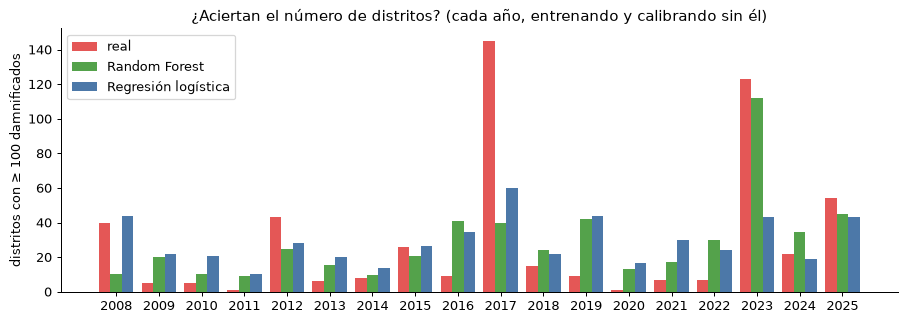

anio,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
real,40,5,5,1,43,6,8,26,9,145,15,9,1,7,7,123,22,54
Random Forest,10,20,10,9,25,15,10,21,41,40,24,42,13,17,30,112,34,45
Regresión logística,44,22,21,11,28,20,14,26,35,60,22,44,16,30,24,43,19,43
Promedio de los dos,27,21,16,10,27,18,12,24,38,50,23,43,15,24,27,78,27,44


In [5]:
def bosque():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEMILLA))


def a_logaritmo(X):
    X = X.copy()
    for col in EN_LOGARITMO:
        if col in X:
            X[col] = np.log1p(X[col])
    return X


def logistica():
    return make_pipeline(FunctionTransformer(a_logaritmo), SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=5000))


MODELOS = {"Random Forest": {"crear": bosque, "variables": ESCENARIO, "desde": 1970},
           "Regresión logística": {"crear": logistica, "variables": IMPACTO, "desde": 2003}}


def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p)).reshape(-1, 1)


def calibrador(datos):
    return LogisticRegression(C=1e6).fit(logit(datos.puntaje), datos.alta_incidencia)


ANIOS_CALIBRACION = range(2008, 2026)
fuera_de_tiempo = {}
for nombre, m in MODELOS.items():
    partes = []
    for anio in ANIOS_CALIBRACION:
        entreno = df[(df.anio < anio) & (df.anio >= m["desde"])]
        prueba = df[df.anio == anio]
        modelo = m["crear"]().fit(entreno[m["variables"]], entreno.alta_incidencia)
        partes.append(prueba[["ubigeo", "anio", "alta_incidencia"]]
                      .assign(puntaje=modelo.predict_proba(prueba[m["variables"]])[:, 1]))
    fuera_de_tiempo[nombre] = pd.concat(partes)

conteos, rocs = [], []
for anio in ANIOS_CALIBRACION:
    fila, probs = {"anio": anio}, []
    for nombre, o in fuera_de_tiempo.items():
        f = o[o.anio == anio]
        p = calibrador(o[o.anio != anio]).predict_proba(logit(f.puntaje))[:, 1]
        fila[nombre] = p.sum()
        probs.append(p)
    fila["real"] = f.alta_incidencia.sum()
    fila["Promedio de los dos"] = np.mean(probs, axis=0).sum()
    conteos.append(fila)
    if anio in (2017, 2023):
        rocs.append({"anio": anio, **{n: roc_auc_score(f.alta_incidencia, p) for n, p in zip(MODELOS, probs)},
                     "Promedio de los dos": roc_auc_score(f.alta_incidencia, np.mean(probs, axis=0))})
conteos = pd.DataFrame(conteos).set_index("anio")
print("ROC-AUC al ordenar los distritos (0,5 = azar):")
display(pd.DataFrame(rocs).set_index("anio").round(3))

fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(len(conteos))
for i, (col, color) in enumerate([("real", "#E45756"), ("Random Forest", "#54A24B"), ("Regresión logística", "#4C78A8")]):
    ax.bar(x + (i - 1) * 0.27, conteos[col], 0.27, color=color, label=col)
ax.set_xticks(x, conteos.index)
ax.set_ylabel(f"distritos con ≥ {UMBRAL_ALTA} damnificados")
ax.set_title("¿Aciertan el número de distritos? (cada año, entrenando y calibrando sin él)")
ax.legend()
plt.show()
conteos[["real", "Random Forest", "Regresión logística", "Promedio de los dos"]].round(0).astype(int).T

## 6. Predicción 2027

Cada modelo da una probabilidad por distrito. El nivel de riesgo usa el **promedio de los dos**:

| Nivel | Probabilidad promedio de tener 100 damnificados o más |
|---|---|
| Muy alto | 0,6 o más |
| Alto | de 0,4 a 0,6 |
| Medio | de 0,2 a 0,4 |
| Bajo | menos de 0,2 |

La suma de las probabilidades es el **número esperado de distritos con alta incidencia**. Se muestra para cada
modelo, para ver el rango.

Distritos esperados con alta incidencia (tres primeras columnas) y distritos por nivel (el resto):


,Random Forest,Regresión logística,Promedio,Muy alto,Alto,Medio,Bajo
escenario,,,,,,,
Lluvia normal,54,31,43,1,23,27,313
Lluvia como 2023,87,64,75,14,51,78,221
Lluvia como 2017,93,80,87,27,59,78,200
Lluvia como 1998,105,118,111,70,57,64,173
Peor caso por distrito,107,118,112,66,62,73,163
Lluvia como 1998 +25 %,111,138,125,88,44,89,143
Lluvia como 1998 +50 %,113,157,135,97,46,104,117


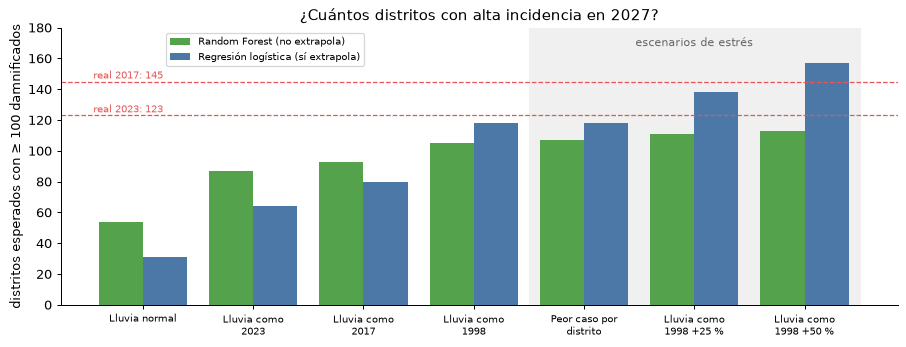

Distritos esperados con alta incidencia por departamento (promedio de los dos modelos):


escenario,Lluvia normal,Lluvia como 2023,Lluvia como 2017,Lluvia como 1998,Peor caso por distrito,Lluvia como 1998 +25 %,Lluvia como 1998 +50 %
departamento,,,,,,,
TUMBES,2,4,5,7,7,8,8
PIURA,20,27,32,42,42,44,44
LAMBAYEQUE,6,15,18,22,21,23,24
LA LIBERTAD,8,14,16,20,21,24,28
ANCASH,7,15,15,20,21,25,29


In [6]:
finales, calibradores = {}, {}
for nombre, m in MODELOS.items():
    datos = df[df.anio >= m["desde"]]
    finales[nombre] = m["crear"]().fit(datos[m["variables"]], datos.alta_incidencia)
    calibradores[nombre] = calibrador(fuera_de_tiempo[nombre])
CLAVE_MODELO = {"Random Forest": "prob_random_forest", "Regresión logística": "prob_logistica"}
NIVELES = ["Bajo", "Medio", "Alto", "Muy alto"]
CORTES = [0, 0.2, 0.4, 0.6, 1.01]


def predecir(filas):
    out = pd.DataFrame({"ubigeo": filas.index, "distrito": filas.distrito.values, "provincia": filas.provincia.values,
                        "departamento": filas.departamento.values})
    for nombre, m in MODELOS.items():
        puntaje = finales[nombre].predict_proba(filas[m["variables"]])[:, 1]
        out[CLAVE_MODELO[nombre]] = calibradores[nombre].predict_proba(logit(puntaje))[:, 1].round(3)
    out["probabilidad"] = out[list(CLAVE_MODELO.values())].mean(axis=1).round(3)
    return out


riesgo = pd.concat([predecir(f).assign(escenario=n) for n, f in filas_2027.items()], ignore_index=True)
riesgo["nivel"] = pd.cut(riesgo.probabilidad, CORTES, labels=NIVELES, right=False)
riesgo["puesto"] = riesgo.groupby("escenario").probabilidad.rank(ascending=False, method="min").astype(int)

resumen = riesgo.groupby("escenario")[["prob_random_forest", "prob_logistica", "probabilidad"]].sum()
resumen.columns = ["Random Forest", "Regresión logística", "Promedio"]
resumen = pd.concat([resumen.round(0).astype(int), pd.crosstab(riesgo.escenario, riesgo.nivel)[NIVELES[::-1]]],
                    axis=1).loc[orden_esc]
real_2017 = df[df.anio == 2017].alta_incidencia.sum()
real_2023 = df[df.anio == 2023].alta_incidencia.sum()
print("Distritos esperados con alta incidencia (tres primeras columnas) y distritos por nivel (el resto):")
display(resumen)

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(orden_esc))
ax.bar(x - 0.2, resumen["Random Forest"], 0.4, color="#54A24B", label="Random Forest (no extrapola)")
ax.bar(x + 0.2, resumen["Regresión logística"], 0.4, color="#4C78A8", label="Regresión logística (sí extrapola)")
for valor, texto in [(real_2017, "real 2017"), (real_2023, "real 2023")]:
    ax.axhline(valor, color="#E45756", ls="--", lw=1)
    ax.text(-0.45, valor + 2, f"{texto}: {valor}", color="#E45756", ha="left", fontsize=8)
ax.axvspan(3.5, len(orden_esc) - 0.5, color="0.94", zorder=0)
ax.text(5, 168, "escenarios de estrés", ha="center", color="0.4", fontsize=9)
ax.set_ylim(0, 180)
ax.set_xticks(x, [textwrap.fill(e, 14) for e in orden_esc], fontsize=8)
ax.set_ylabel(f"distritos esperados con ≥ {UMBRAL_ALTA} damnificados")
ax.set_title("¿Cuántos distritos con alta incidencia en 2027?")
ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(0.12, 1))
fig.savefig(RESULTADOS / "figuras" / "riesgo_2027_distritos_esperados.png", dpi=130, bbox_inches="tight")
plt.show()

print("Distritos esperados con alta incidencia por departamento (promedio de los dos modelos):")
(riesgo.pivot_table(index="departamento", columns="escenario", values="probabilidad", aggfunc="sum")[orden_esc]
 .loc[["TUMBES", "PIURA", "LAMBAYEQUE", "LA LIBERTAD", "ANCASH"]].round(0).astype(int))

## 7. Mapa de riesgo

Un mapa por escenario, con los mismos colores. La fila de abajo son los escenarios de estrés.

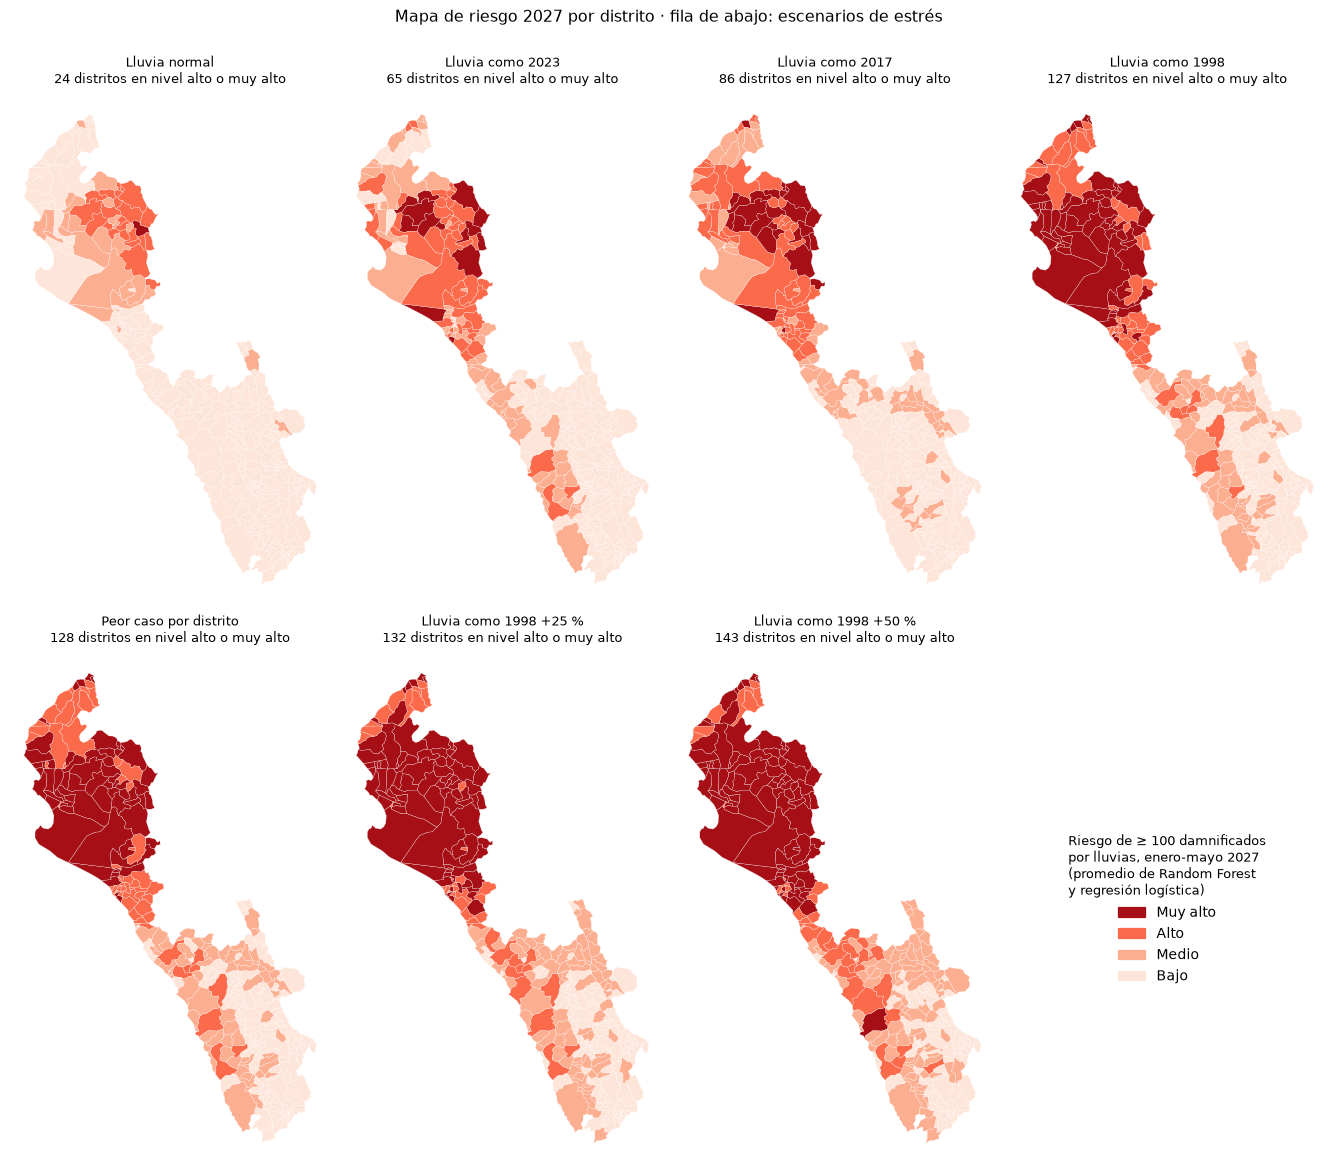

In [7]:
gj = json.loads((LIMPIOS / "territorio" / "distritos_costa_norte.geojson").read_text())
geoms = {f["properties"]["ubigeo"]: shape(f["geometry"]) for f in gj["features"]}
COLORES = {"Bajo": "#fee5d9", "Medio": "#fcae91", "Alto": "#fb6a4a", "Muy alto": "#a50f15"}

fig, ejes = plt.subplots(2, 4, figsize=(15, 13))
for ax, esc in zip(ejes.flat, orden_esc):
    niv = riesgo[riesgo.escenario == esc].set_index("ubigeo").nivel
    for ubigeo, g in geoms.items():
        for parte in getattr(g, "geoms", [g]):
            ax.fill(*parte.exterior.xy, color=COLORES[niv[ubigeo]], ec="white", lw=0.2)
    ax.set_title(f"{esc}\n{niv.isin(['Alto', 'Muy alto']).sum()} distritos en nivel alto o muy alto", fontsize=10)
    ax.set_aspect("equal")
    ax.axis("off")
ejes.flat[-1].axis("off")
ejes.flat[-1].legend(handles=[Patch(color=COLORES[n], label=n) for n in NIVELES[::-1]], loc="center",
                     frameon=False, fontsize=11,
                     title=f"Riesgo de ≥ {UMBRAL_ALTA} damnificados\npor lluvias, enero-mayo 2027\n"
                           "(promedio de Random Forest\ny regresión logística)")
fig.suptitle("Mapa de riesgo 2027 por distrito · fila de abajo: escenarios de estrés", fontsize=13, y=1.0)
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.01, wspace=0.02, hspace=0.08)
fig.savefig(RESULTADOS / "figuras" / "mapa_riesgo_2027.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. Distritos prioritarios

Un distrito es **prioritario** si queda en nivel alto o muy alto en los tres escenarios históricos de Niño
(lluvia como en 2023, 2017 y 1998). Es la lista que menos depende de cómo llueva. Después se ven los distritos que
**se suman** si llueve 50 % más que en 1998: los que pasan a nivel alto o muy alto y no lo estaban con lluvia como
1998.

In [8]:
NINO = ["Lluvia como 2023", "Lluvia como 2017", "Lluvia como 1998"]
ESTRES = "Lluvia como 1998 +50 %"
niveles = riesgo.pivot(index="ubigeo", columns="escenario", values="nivel")
alto = niveles.isin(["Alto", "Muy alto"])
prioritarios = alto[NINO].all(axis=1)
tabla = riesgo.pivot_table(index=["ubigeo", "distrito", "provincia", "departamento"], columns="escenario",
                           values="probabilidad")[NINO + [ESTRES]]
tabla["promedio Niño"] = tabla[NINO].mean(axis=1)
u = tabla.index.get_level_values("ubigeo")
lista = tabla[prioritarios.reindex(u).values].sort_values("promedio Niño", ascending=False)
print(f"{len(lista)} distritos prioritarios. Por departamento:")
print(lista.reset_index().departamento.value_counts().to_string())
nuevos = tabla[(alto[ESTRES] & ~alto["Lluvia como 1998"]).reindex(u).values]
nuevos = nuevos.assign(sube=nuevos[ESTRES] - nuevos["Lluvia como 1998"]).sort_values(ESTRES, ascending=False)
print(f"\nCon lluvia como 1998 +50 % se suman {len(nuevos)} distritos a los de nivel alto o muy alto. Por departamento:")
print(nuevos.reset_index().departamento.value_counts().to_string())
print("\nLos 25 prioritarios con mayor probabilidad promedio:")
display(lista.head(25).round(2))
print("Los 10 con mayor probabilidad entre los que se suman:")
nuevos.head(10).round(2)

60 distritos prioritarios. Por departamento:
departamento
PIURA          37
LAMBAYEQUE     19
TUMBES          2
LA LIBERTAD     2

Con lluvia como 1998 +50 % se suman 16 distritos a los de nivel alto o muy alto. Por departamento:
departamento
LA LIBERTAD    11
ANCASH          4
LAMBAYEQUE      1

Los 25 prioritarios con mayor probabilidad promedio:


,,,escenario,Lluvia como 2023,Lluvia como 2017,Lluvia como 1998,Lluvia como 1998 +50 %,promedio Niño
ubigeo,distrito,provincia,departamento,,,,,
200401,CHULUCANAS,MORROPON,PIURA,0.71,0.75,0.79,0.78,0.75
200104,CASTILLA,PIURA,PIURA,0.66,0.71,0.85,0.83,0.74
200405,MORROPON,MORROPON,PIURA,0.64,0.73,0.80,0.82,0.72
200114,TAMBO GRANDE,PIURA,PIURA,0.65,0.71,0.76,0.75,0.71
200601,SULLANA,SULLANA,PIURA,0.62,0.68,0.81,0.78,0.71
240101,TUMBES,TUMBES,TUMBES,0.60,0.70,0.80,0.81,0.70
200301,HUANCABAMBA,HUANCABAMBA,PIURA,0.69,0.72,0.68,0.77,0.70
200201,AYABACA,AYABACA,PIURA,0.64,0.71,0.70,0.74,0.68
200111,LAS LOMAS,PIURA,PIURA,0.60,0.66,0.75,0.75,0.67


Los 10 con mayor probabilidad entre los que se suman:


,,,escenario,Lluvia como 2023,Lluvia como 2017,Lluvia como 1998,Lluvia como 1998 +50 %,promedio Niño,sube
ubigeo,distrito,provincia,departamento,,,,,,
131201,VIRU,VIRU,LA LIBERTAD,0.23,0.13,0.40,0.53,0.25,0.13
130703,JEQUETEPEQUE,PACASMAYO,LA LIBERTAD,0.28,0.23,0.39,0.51,0.30,0.11
130110,SIMBAL,TRUJILLO,LA LIBERTAD,0.19,0.20,0.39,0.50,0.26,0.11
130208,CASA GRANDE,ASCOPE,LA LIBERTAD,0.24,0.24,0.35,0.46,0.28,0.11
131202,CHAO,VIRU,LA LIBERTAD,0.17,0.09,0.32,0.45,0.20,0.13
020801,CASMA,CASMA,ANCASH,0.44,0.20,0.35,0.45,0.33,0.10
130613,SINSICAP,OTUZCO,LA LIBERTAD,0.15,0.19,0.32,0.44,0.22,0.12
020804,YAUTAN,CASMA,ANCASH,0.33,0.26,0.34,0.43,0.31,0.10
021804,MACATE,SANTA,ANCASH,0.28,0.12,0.35,0.43,0.25,0.08


## 9. ¿Cuánto cambia si el ICEN es otro?

Tu supuesto pone el ICEN de enero de 2027 en 3,2, pero el ICEN ya marcó 4,50 en setiembre de 2026. Aquí se repite
la predicción cambiando solo el ICEN de enero a mayo. Solo afecta al Random Forest, porque la regresión logística
no usa el ICEN.

In [9]:
ref_1998 = df[df.anio == 1998].iloc[0]
VARIANTES_ICEN = {
    "Supuesto del proyecto": (ICEN_ENE_MAY_2027.max(), round(ICEN_ENE_MAY_2027.mean(), 2)),
    "ICEN como en 1998": (ref_1998.icen_max_ene_may, ref_1998.icen_medio_ene_may),
    "ICEN neutro (0)": (0.0, 0.0),
}
sens = {}
for variante, (icen_max, icen_medio) in VARIANTES_ICEN.items():
    sens[f"{variante} (máx {icen_max:.1f}, medio {icen_medio:.1f})"] = {
        esc: predecir(f.assign(icen_max_ene_may=icen_max, icen_medio_ene_may=icen_medio)).probabilidad.sum()
        for esc, f in filas_2027.items()}
print("Distritos esperados con alta incidencia (promedio de los dos modelos) según el ICEN de enero a mayo:")
pd.DataFrame(sens).T[orden_esc].round(0).astype(int)

Distritos esperados con alta incidencia (promedio de los dos modelos) según el ICEN de enero a mayo:


,Lluvia normal,Lluvia como 2023,Lluvia como 2017,Lluvia como 1998,Peor caso por distrito,Lluvia como 1998 +25 %,Lluvia como 1998 +50 %
"Supuesto del proyecto (máx 3.2, medio 2.3)",43,75,87,111,112,125,135
"ICEN como en 1998 (máx 3.5, medio 3.0)",43,75,87,111,112,125,135
"ICEN neutro (0) (máx 0.0, medio 0.0)",27,50,60,83,83,96,106


## 10. Archivos

- `resultados/riesgo_2027_distritos.csv`: una fila por distrito y escenario, con la probabilidad de cada modelo,
  el promedio, el nivel y el puesto.
- `resultados/mapa_riesgo_2027.geojson`: el mapa con la probabilidad y el nivel de cada escenario, y si el distrito es
  prioritario. Se abre en QGIS, geojson.io o Google Earth Engine.
- `resultados/figuras/mapa_riesgo_2027.png` y `resultados/figuras/riesgo_2027_distritos_esperados.png`.

In [10]:
riesgo.to_csv(RESULTADOS / "riesgo_2027_distritos.csv", index=False)

CLAVES = {"Lluvia normal": "normal", "Lluvia como 2023": "como_2023", "Lluvia como 2017": "como_2017",
          "Lluvia como 1998": "como_1998", "Peor caso por distrito": "peor_caso",
          "Lluvia como 1998 +25 %": "como_1998_mas25", "Lluvia como 1998 +50 %": "como_1998_mas50"}
r = riesgo.set_index(["ubigeo", "escenario"])
for f in gj["features"]:
    u = f["properties"]["ubigeo"]
    for esc, clave in CLAVES.items():
        f["properties"][f"prob_{clave}"] = float(r.loc[(u, esc), "probabilidad"])
        f["properties"][f"nivel_{clave}"] = str(r.loc[(u, esc), "nivel"])
    f["properties"]["prioritario"] = bool(prioritarios[u])
(RESULTADOS / "mapa_riesgo_2027.geojson").write_text(json.dumps(gj, ensure_ascii=False))
print("Guardados: riesgo_2027_distritos.csv, mapa_riesgo_2027.geojson y las dos figuras")

Guardados: riesgo_2027_distritos.csv, mapa_riesgo_2027.geojson y las dos figuras


## 11. Conclusiones

**1. Más lluvia que en 1998 sí agranda el mapa, sobre todo fuera de Piura.**
Con lluvia como en 1998 quedan 127 distritos en nivel alto o muy alto; con 50 % más lluvia, 143. Piura y Tumbes
ya están casi completos con la lluvia de 1998, así que los que se suman están más al sur: 11 en La Libertad
(Virú, Jequetepeque, Simbal, Casa Grande, Chao…), 4 en Áncash (Casma, Yaután…) y 1 en Lambayeque.

**2. La regresión logística sigue subiendo; el Random Forest se queda plano.**
De lluvia como en 1998 a 1998 +50 %, los distritos esperados con alta incidencia pasan de 118 a 157 con la
regresión logística, pero solo de 105 a 113 con el Random Forest. Es la diferencia entre un modelo que extrapola y
uno que no. El promedio de los dos va de 111 a 135.

**3. Dónde: la lista prioritaria es estable.**
60 distritos quedan en nivel alto o muy alto con lluvia como en 2023, 2017 y 1998: 37 en Piura, 19 en Lambayeque,
2 en Tumbes y 2 en La Libertad. Encabezan Chulucanas, Castilla, Morropón, Tambo Grande, Sullana, Tumbes,
Huancabamba y Ayabaca.

**4. Cuánto: los números son probablemente un piso.**
Al validar, los dos modelos se quedaron cortos en los años extremos. Para 2017 esperaban 40 (Random Forest) y 60
(regresión logística), y hubo 145. Para 2023 esperaban 112 y 43, y hubo 123. Además, en 2017 y 2023 llovió menos
que en 1998 (182 % y 130 % de lo normal en promedio, contra 324 %) y aun así hubo 123 a 145 distritos con alta
incidencia. Si 2027 trae lluvias como las de 1998 o mayores, es razonable esperar al menos esa cantidad.

**5. 1998 no se pudo corregir.**
En 1998 DesInventar registró damnificados en solo 9 distritos de Piura; INDECI registró 59 en 2017. Multiplicar
sus cifras no cambia nada, porque los distritos que faltan quedan en cero. Por eso la regresión logística aprende
solo de INDECI y la lluvia de 1998 entra como escenario, no como ejemplo de daño.

**6. Tu supuesto del ICEN casi no pesa mientras el Niño siga fuerte.**
Con tu supuesto o con un ICEN como el de 1998 salen los mismos números. Con ICEN neutro de enero a mayo, los
distritos esperados bajan entre 21 % y 37 % según el escenario. Solo el Random Forest usa el ICEN.

**Límites que conviene decir en la exposición**
- Los escenarios de +25 % y +50 % son supuestos de estrés, no pronósticos.
- La regresión logística extrapola en línea recta (en escala logit). Es una hipótesis, no algo que los datos
  confirmen.
- Las probabilidades se calibraron con 2008-2025, donde solo hay dos años extremos.
- La población es la de 2020: no se consideró su crecimiento hasta 2027.
- La temporada 2026 todavía no está en la base de INDECI.
- La variable objetivo son emergencias con damnificados registradas, no el área inundada.

## 12. Cómo actualizarlo

- **Cuando ENFEN publique un ICEN nuevo:** corre `scripts/01_descargar_clima.py`, `05_preparar_historicos.py` y
  `07_panel_distrito_temporada.py`, y luego este notebook.
- **Si cambias tu supuesto del ICEN 2027:** edita `datos/2_limpios/escenarios/icen_2027_supuesto.csv` y vuelve a
  correr este notebook.
- **Cuando INDECI publique 2026:** ponla en `datos/1_crudos/INDECI_SINPAD/` y corre 02, 05 y 07.
- **Si SENAMHI publica un pronóstico de lluvia:** agrégalo como un escenario más en la sección 4. Es la mejor forma
  de pasar de escenarios a un pronóstico.
